In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

df_raw = pd.read_csv("messy_customer_orders.csv")
df = df_raw.copy()
df.head(10)

,customer_id,name,gender,age,signup_date,city,order_amount,quantity,payment_method,rating
0,1348,Priya Singh,Male,29.0,07/12/2021,Delhi,389.3,9.0,CC,3.0
1,1615,Priya Singh,Male,35.0,08/07/2023,NaN,960.82,1.0,CC,3.0
2,1701,Rahul Singh,NaN,27.0,18/01/2022,mumbai,116.72,9.0,Credit Card,1.0
3,1949,Karan Joshi,male,25.0,30/04/2021,Kolkata,$304.90,8.0,credit card,2.0
4,1706,Aarav Reddy,Female,18.0,21/12/2021,Mumbai,NaN,3.0,Credit Card,3.0
5,1067,Priya Reddy,Male,43.0,24/01/2023,NaN,132.53,7.0,Cash,2.0
6,1214,Rahul Joshi,Male,33.0,"Nov 12, 2023",mumbai,$564.88,4.0,CC,4.0
7,1438,Arjun Reddy,Female,29.0,"Oct 10, 2022",DELHI,308.32,4.0,UPI,1.0
8,1068,Divya Gupta,Male,18.0,2023-01-18,Mumbai,$604.76,4.0,UPI,5.0
9,1689,isha mehta,Male,45.0,26/07/2022,DELHI,$239.25,1.0,Credit Card,NaN


## 1. Data Quality Report (before cleaning)

In [3]:
print("Shape:", df.shape)
print("\nDtypes:"); print(df.dtypes)
print("\nNull counts:"); print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nNumeric summary:"); df.describe()

Shape: (1050, 10)

Dtypes:
customer_id         int64
name               object
gender             object
age               float64
signup_date        object
city               object
order_amount       object
quantity          float64
payment_method     object
rating            float64
dtype: object

Null counts:
customer_id         0
name                0
gender            103
age                38
signup_date        24
city              111
order_amount       37
quantity           23
payment_method      0
rating             62
dtype: int64

Duplicate rows: 50

Numeric summary:


,customer_id,age,quantity,rating
count,1050.000000,1012.000000,1027.000000,988.000000
mean,1499.154286,38.851779,5.667965,3.006073
std,288.582382,55.664867,2.854116,1.422059
min,1001.000000,-5.000000,1.000000,1.000000
25%,1250.250000,26.000000,3.000000,2.000000
50%,1498.500000,35.000000,6.000000,3.000000
75%,1745.750000,42.000000,8.000000,4.000000
max,2000.000000,999.000000,10.000000,5.000000


In [4]:
# Value range anomalies and inconsistent categories
print("Age min/max:", pd.to_numeric(df['age'], errors='coerce').min(), pd.to_numeric(df['age'], errors='coerce').max())
for col in ["gender","city","payment_method"]:
    print(f"\n{col}:"); print(df[col].value_counts(dropna=False))
print("\nSample signup_date values:"); print(df['signup_date'].dropna().sample(8, random_state=0).tolist())
print("\nSample order_amount values:"); print(df['order_amount'].dropna().sample(8, random_state=0).tolist())

Age min/max: -5.0 999.0

gender:
gender
Male        259
Female      235
male        128
female      108
NaN         103
F            92
M            62
MALE         38
 Female      25
Name: count, dtype: int64

city:
city
NaN          111
mumbai       101
Chennai       93
DELHI         92
 Chennai      92
Mumbai        88
Bangalore     86
delhi         84
Kolkata       82
bangalore     77
Delhi         73
Bengaluru     71
Name: count, dtype: int64

payment_method:
payment_method
credit card    150
Credit Card    117
Debit Card     116
upi            116
UPI            113
CC             112
debit card     111
Cash           109
cash           106
Name: count, dtype: int64

Sample signup_date values:
['Dec 17, 2022', '2021-01-31', '2022-07-01', '2022-06-26', 'May 03, 2021', '08/07/2023', '29/03/2022', '08/06/2023']

Sample order_amount values:
['$939.00', '$700.56', '202.84', '843.01', '395.4', '202.61', '960.82', '330.21']


### Observations
- `customer_id` is stored as an integer; it is an identifier and should be a string.
- `signup_date` and `order_amount` are `object` (text): dates come in 3 formats and amounts include `$` and commas.
- `gender`, `city`, `payment_method` have inconsistent spelling, case and whitespace (e.g. `M`, `male`, `Male`; `CC`, `Credit Card`).
- `age` contains impossible values (negative, 250, 999).
- There are exact duplicate rows and several columns with nulls.

> *Update these notes to match the exact numbers in your output above.*

## 2. Duplicate Removal
**Decision:** Remove exact duplicate rows (all columns identical). A repeated record would inflate order counts and revenue. I keep the first occurrence.

In [5]:
before_rows = len(df)
dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates found: {dups} | Rows before: {before_rows} | Rows after: {len(df)}")

Duplicates found: 50 | Rows before: 1050 | Rows after: 1000


## 3. Standardisation of Text Columns
Strip whitespace and unify case first, then map variants to a single label.

In [6]:
# Gender
df["gender"] = df["gender"].str.strip().str.lower().map({"male":"Male","m":"Male","female":"Female","f":"Female"})

# City
df["city"] = df["city"].str.strip().str.title().replace({"Bangalore":"Bengaluru"})

# Payment method
df["payment_method"] = (df["payment_method"].str.strip().str.lower()
    .map({"credit card":"Credit Card","cc":"Credit Card","debit card":"Debit Card","upi":"UPI","cash":"Cash"}))

# Name
df["name"] = df["name"].str.strip().str.title()

for col in ["gender","city","payment_method"]:
    print(f"\n{col}:"); print(df[col].value_counts(dropna=False))


gender:
gender
Male      462
Female    437
NaN       101
Name: count, dtype: int64

city:
city
Delhi        241
Bengaluru    227
Mumbai       175
Chennai      175
NaN          103
Kolkata       79
Name: count, dtype: int64

payment_method:
payment_method
Credit Card    358
Debit Card     219
UPI            218
Cash           205
Name: count, dtype: int64


**Result:** `gender` now has 2 categories, `payment_method` 4, and `city` 5 clean values (Bangalore merged into Bengaluru). Missing gender and city values stay as NaN for now and are handled in the next section.

## 4. Data Type Correction

In [7]:
# IDs as string
df["customer_id"] = df["customer_id"].astype(str)

# Dates: three mixed formats -> datetime
def parse_date(x):
    if pd.isna(x): return pd.NaT
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%b %d, %Y"):
        try: return pd.to_datetime(x, format=fmt)
        except (ValueError, TypeError): continue
    return pd.NaT
df["signup_date"] = df["signup_date"].apply(parse_date)

# Money: remove $ and commas, convert to float
df["order_amount"] = pd.to_numeric(df["order_amount"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")

print(df.dtypes)
print("Unparseable dates:", df["signup_date"].isnull().sum())

customer_id               object
name                      object
gender                    object
age                      float64
signup_date       datetime64[ns]
city                      object
order_amount             float64
quantity                 float64
payment_method            object
rating                   float64
dtype: object
Unparseable dates: 22


**Decision:** Dates are parsed with explicit formats (safer than guessing). Note that `dd/mm/yyyy` is assumed for slash dates. Anything unparseable becomes `NaT`.

## 5. Outlier Detection
- **Age:** values below 18 or above 100 are *impossible* (data-entry errors), so they are set to NaN and imputed (not capped).
- **Order amount, quantity:** use the **IQR method** to detect outliers.

Impossible ages set to NaN: 10
order_amount: bounds=(-226.8, 1128.7) outliers=49
quantity: bounds=(-4.5, 15.5) outliers=0
rating: bounds=(-1.0, 7.0) outliers=0


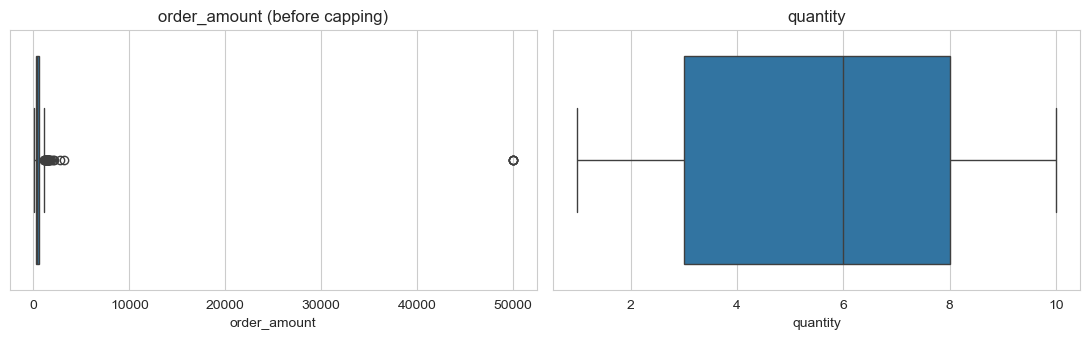

In [8]:
# Impossible ages -> NaN
bad_age = ((df["age"] < 18) | (df["age"] > 100)).sum()
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan
print("Impossible ages set to NaN:", bad_age)

def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

for col in ["order_amount", "quantity", "rating"]:
    lo, hi = iqr_bounds(df[col].dropna())
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: bounds=({lo:.1f}, {hi:.1f}) outliers={n_out}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=df["order_amount"], ax=ax[0]).set_title("order_amount (before capping)")
sns.boxplot(x=df["quantity"], ax=ax[1]).set_title("quantity")
plt.tight_layout(); plt.show()

In [9]:
# Cap order_amount at the IQR upper bound (winsorise)
lo, hi = iqr_bounds(df["order_amount"].dropna())
n_cap = (df["order_amount"] > hi).sum()
df["order_amount"] = df["order_amount"].clip(upper=hi)
print(f"Capped {n_cap} order_amount values at {hi:.2f}")

Capped 49 order_amount values at 1128.74


**Decisions**
| Column | Decision | Reason |
|---|---|---|
| age | Impossible values → NaN, then impute | Not real customers aged 250; error, not signal |
| order_amount | **Cap** at IQR upper bound | Sales amounts are right-skewed; a few `50000` values are likely typos but still real orders, so capping keeps the rows without distorting the mean |
| quantity, rating | **Retain** | No outliers flagged / values lie in a valid range |

## 6. Missing Data Handling
| Column | Strategy | Justification |
|---|---|---|
| age | **Median** imputation | Roughly symmetric but median is robust to any residual extremes |
| gender | Fill with **"Unknown"** | Guessing a person's gender would be fabricating data; a separate category is honest |
| city | Fill with **"Unknown"** | Same reason: location is categorical and not inferable |
| signup_date | **Drop row** | Only a tiny share is missing and a date cannot be sensibly imputed |
| order_amount | **Median** imputation | Right-skewed distribution, so median beats mean |
| quantity | **Mode** imputation | Discrete count; most common value is a valid quantity |
| rating | **Median** imputation | Ordinal 1–5 scale; median keeps it a valid rating |

In [10]:
print("Nulls before imputation:"); print(df.isnull().sum()); print()

df = df.dropna(subset=["signup_date"])
df["age"] = df["age"].fillna(df["age"].median())
df["order_amount"] = df["order_amount"].fillna(df["order_amount"].median())
df["quantity"] = df["quantity"].fillna(df["quantity"].mode()[0])
df["rating"] = df["rating"].fillna(df["rating"].median())
df["gender"] = df["gender"].fillna("Unknown")
df["city"] = df["city"].fillna("Unknown")

# Final dtype polish
df["age"] = df["age"].round().astype(int)
df["quantity"] = df["quantity"].astype(int)
df["rating"] = df["rating"].astype(int)
df["order_amount"] = df["order_amount"].astype(float)
df = df.reset_index(drop=True)

print("Nulls after imputation:"); print(df.isnull().sum())

Nulls before imputation:
customer_id         0
name                0
gender            101
age                45
signup_date        22
city              103
order_amount       36
quantity           22
payment_method      0
rating             60
dtype: int64

Nulls after imputation:
customer_id       0
name              0
gender            0
age               0
signup_date       0
city              0
order_amount      0
quantity          0
payment_method    0
rating            0
dtype: int64


## 7. Before vs. After Summary

In [11]:
expected = {"customer_id":"O","name":"O","gender":"O","age":"if","signup_date":"M",
            "city":"O","order_amount":"f","quantity":"if","payment_method":"O","rating":"if"}

def dtype_accuracy(d):
    ok = sum(d[c].dtype.kind in k for c, k in expected.items())
    return f"{ok}/{len(expected)}"

summary = pd.DataFrame({
    "Metric": ["Row count", "Total null cells", "Duplicate rows", "Columns with correct dtype"],
    "Before": [len(df_raw), int(df_raw.isnull().sum().sum()), int(df_raw.duplicated().sum()), dtype_accuracy(df_raw)],
    "After":  [len(df), int(df.isnull().sum().sum()), int(df.duplicated().sum()), dtype_accuracy(df)],
})
summary

,Metric,Before,After
0,Row count,1050,978
1,Total null cells,398,0
2,Duplicate rows,50,0
3,Columns with correct dtype,7/10,10/10


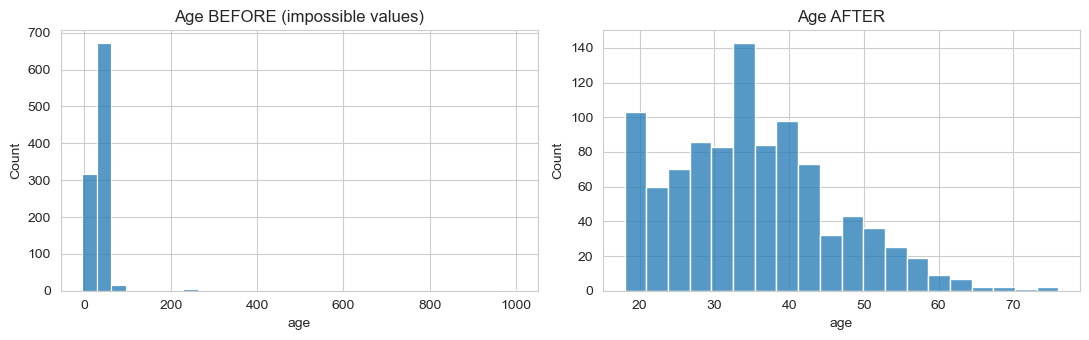

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,978,978,1348,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,978,120,Ananya Verma,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,978,3,Male,453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,978.0,NaN,NaN,NaN,34.98364,18.0,27.0,34.0,42.0,76.0,10.907902
signup_date,978,NaN,NaN,NaN,2022-06-15 01:10:40.490797568,2021-01-01 00:00:00,2021-09-05 00:00:00,2022-05-26 00:00:00,2023-03-12 06:00:00,2023-12-28 00:00:00,NaN
city,978,6,Delhi,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_amount,978.0,NaN,NaN,NaN,476.478742,48.54,285.24,410.77,611.9725,1128.745,270.150117
quantity,978.0,NaN,NaN,NaN,5.752556,1.0,3.0,6.0,8.0,10.0,2.841086
payment_method,978,4,Credit Card,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,978.0,NaN,NaN,NaN,3.015337,1.0,2.0,3.0,4.0,5.0,1.369641


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(pd.to_numeric(df_raw["age"], errors="coerce").dropna(), bins=30, ax=ax[0]).set_title("Age BEFORE (impossible values)")
sns.histplot(df["age"], bins=20, ax=ax[1]).set_title("Age AFTER")
plt.tight_layout(); plt.show()
df.describe(include="all").T

### Observations
Cleaning removed all duplicates and nulls, fixed every column's dtype, collapsed label variants into consistent categories, and replaced impossible ages. Both age plots show the effect: the raw data has spikes far outside any realistic range, while the cleaned data follows a realistic distribution.

*Edit with your actual before/after numbers.*

## 8. Save Cleaned Dataset

In [13]:
df.to_csv("cleaned_customer_orders.csv", index=False)
print("Saved cleaned_customer_orders.csv with shape", df.shape)

Saved cleaned_customer_orders.csv with shape (978, 10)


In [14]:
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: C:\Users\Lenovo\OIBSIP\DataAnalytics-L1-DataCleaning
Files: ['.ipynb_checkpoints', 'cleaned_customer_orders.csv', 'messy_customer_orders.csv', 'README.md', 'Task3_Data_Cleaning.ipynb']


## Conclusion
The raw dataset had duplicates, ~5–10% nulls in several columns, 3 date formats, text-typed numbers, inconsistent categories, and impossible values. Each issue was handled with a documented, justified choice: **delete** exact duplicates and rows with no usable date, **correct** formats and types, **cap** order-value outliers, and **impute** the rest (median for skewed or ordinal data, mode for counts, "Unknown" for categories). The cleaned file is ready for EDA or modelling.

**Limitations:** median imputation reduces variance slightly, and the `dd/mm/yyyy` assumption for slash dates should be confirmed with the data owner in a real project.